# Notebook 03 – Exploratory Data Analysis (EDA)

## Objective

The objective of this notebook is to explore the cleaned patient dataset using statistical summaries and visualizations.

The analysis aims to:

- Understand feature distributions
- Explore relationships between variables
- Detect potential outliers
- Discover patterns useful for Machine Learning
- Generate insights for feature engineering

### Input

data/processed/cleaned_patient_dataset.csv

### Output

- Visualizations
- Insights
- Summary Report

In [14]:
# ==========================================
# Import Required Libraries
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

# (We'll use seaborn for statistical plots)
import seaborn as sns

pd.set_option("display.max_columns", None)

print("Libraries Loaded Successfully")

Libraries Loaded Successfully


In [15]:
# ==========================================
# Load Clean Dataset
# ==========================================

df = pd.read_csv("../data/processed/cleaned_patient_dataset.csv")

print(df.shape)

df.head()

(5000, 29)


,Age,Gender,Height_cm,Weight_kg,BMI,Chronic_Disease,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol_Level,Blood_Sugar_Level,Genetic_Risk_Factor,Allergies,Daily_Steps,Exercise_Frequency,Sleep_Hours,Alcohol_Consumption,Smoking_Habit,Dietary_Habits,Caloric_Intake,Protein_Intake,Carbohydrate_Intake,Fat_Intake,Preferred_Cuisine,Food_Aversions,Recommended_Calories,Recommended_Protein,Recommended_Carbs,Recommended_Fats,Recommended_Meal_Plan
0,56,Other,163,66,24.84,No Disease,175,75,219,124,No,NaN,11452,5,7.6,No,Yes,Vegetarian,2593,105,179,143,Western,NaN,2150,108,139,145,High-Protein Diet
1,69,Female,171,114,38.99,No Disease,155,72,208,72,No,NaN,12962,1,6.3,Yes,No,Vegetarian,1852,69,315,75,Mediterranean,NaN,1527,74,266,80,Balanced Diet
2,46,Female,172,119,40.22,No Disease,137,101,171,145,No,Gluten Intolerance,7898,3,9.9,No,No,Vegetarian,2737,183,103,148,Western,Sweet,2359,180,145,143,High-Protein Diet
3,32,Female,197,118,30.41,No Disease,148,91,258,235,No,Nut Allergy,6602,5,4.2,No,No,Vegetarian,3289,135,371,120,Western,NaN,2858,137,378,135,High-Protein Diet
4,60,Female,156,109,44.79,Hypertension,160,109,260,248,Yes,NaN,9810,2,9.0,No,No,Regular,2405,167,298,48,Indian,Spicy,1937,166,317,56,High-Protein Diet


## Dataset Overview

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       5000 non-null   int64  
 1   Gender                    5000 non-null   object 
 2   Height_cm                 5000 non-null   int64  
 3   Weight_kg                 5000 non-null   int64  
 4   BMI                       5000 non-null   float64
 5   Chronic_Disease           5000 non-null   object 
 6   Blood_Pressure_Systolic   5000 non-null   int64  
 7   Blood_Pressure_Diastolic  5000 non-null   int64  
 8   Cholesterol_Level         5000 non-null   int64  
 9   Blood_Sugar_Level         5000 non-null   int64  
 10  Genetic_Risk_Factor       5000 non-null   object 
 11  Allergies                 1503 non-null   object 
 12  Daily_Steps               5000 non-null   int64  
 13  Exercise_Frequency        5000 non-null   int64  
 14  Sleep_Ho

In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5000.0,48.805600,17.906991,18.00,34.00,49.00,64.0000,79.00
Height_cm,5000.0,174.244000,14.229173,150.00,162.00,174.00,186.0000,199.00
Weight_kg,5000.0,84.366200,20.181030,50.00,67.00,84.00,102.0000,119.00
BMI,5000.0,28.353134,8.297745,12.63,21.85,27.64,33.8125,52.89
Blood_Pressure_Systolic,5000.0,133.982400,26.216215,90.00,111.00,133.00,157.0000,179.00
Blood_Pressure_Diastolic,5000.0,89.735800,17.283025,60.00,75.00,90.00,105.0000,119.00
Cholesterol_Level,5000.0,224.297800,42.918923,150.00,187.00,224.00,261.0000,299.00
Blood_Sugar_Level,5000.0,159.330200,52.149430,70.00,114.00,160.00,204.0000,249.00
Daily_Steps,5000.0,8458.922800,3742.408853,2004.00,5278.75,8452.00,11671.7500,14997.00
Exercise_Frequency,5000.0,2.978200,2.001431,0.00,1.00,3.00,5.0000,6.00


## Age Distribution

This visualization shows the age distribution of patients.

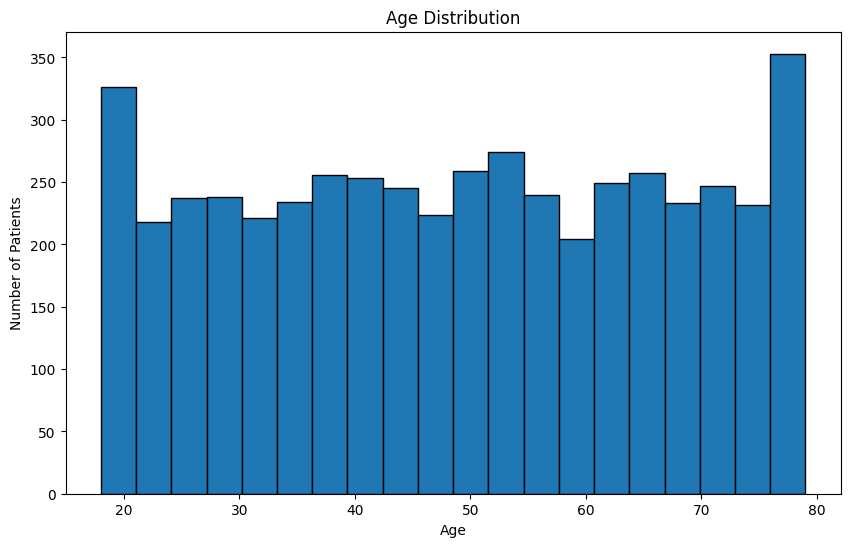

In [18]:
plt.figure(figsize=(10,6))

plt.hist(df["Age"], bins=20, edgecolor="black")

plt.title("Age Distribution")

plt.xlabel("Age")

plt.ylabel("Number of Patients")

plt.savefig("../reports/figures/age_distribution.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

### Observation

The age distribution helps identify whether the dataset contains a balanced representation of younger, middle-aged, and older individuals.

### Inference

A well-distributed age range generally improves the ability of machine learning models to generalize across different age groups.

Gender Distribution

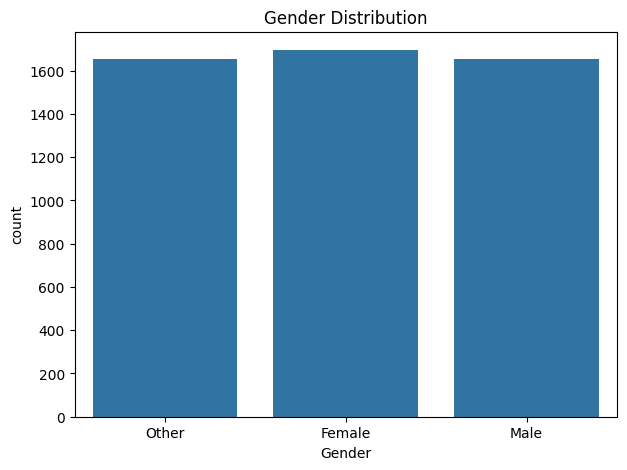

In [19]:
plt.figure(figsize=(7,5))

sns.countplot(data=df,x="Gender")

plt.title("Gender Distribution")

plt.savefig("../reports/figures/gender_distribution.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

Observation
Male, Female and Other genders are almost equally represented.
No gender category is significantly overrepresented.
Interpretation

The dataset is well-balanced with respect to gender, reducing the possibility of gender-related bias during model training.

ML Impact
Gender can safely be included as a predictive feature.
No class balancing is required.

BMI Distribution

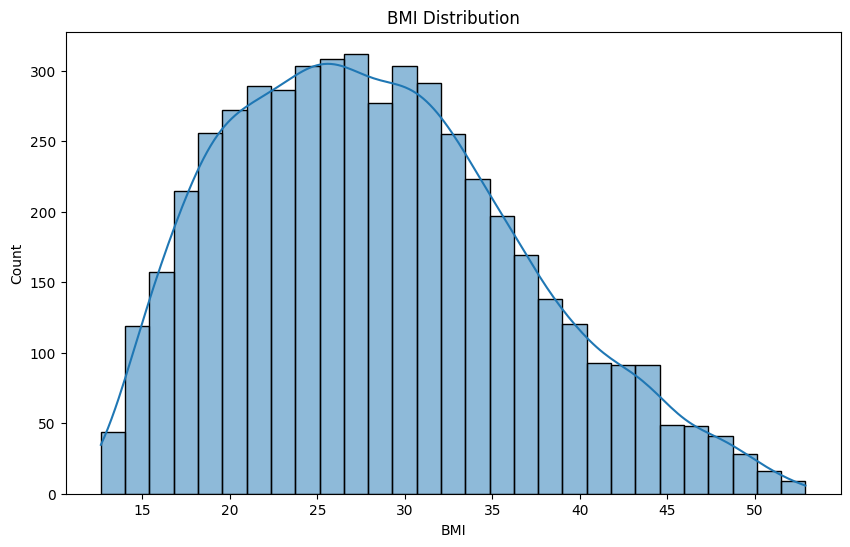

In [20]:
plt.figure(figsize=(10,6))

sns.histplot(df["BMI"], kde=True)

plt.title("BMI Distribution")

plt.savefig("../reports/figures/bmi_distribution.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

Observation

BMI follows an approximately bell-shaped distribution.
Most patients fall between 20 and 35 BMI.
Very few patients have extremely high BMI values.

Interpretation

The dataset represents realistic BMI values.
Slight right skew is expected because obesity cases naturally increase BMI.

ML Impact

BMI is likely to be one of the strongest predictive features.
No transformation is needed at this stage.

Disease Distribution

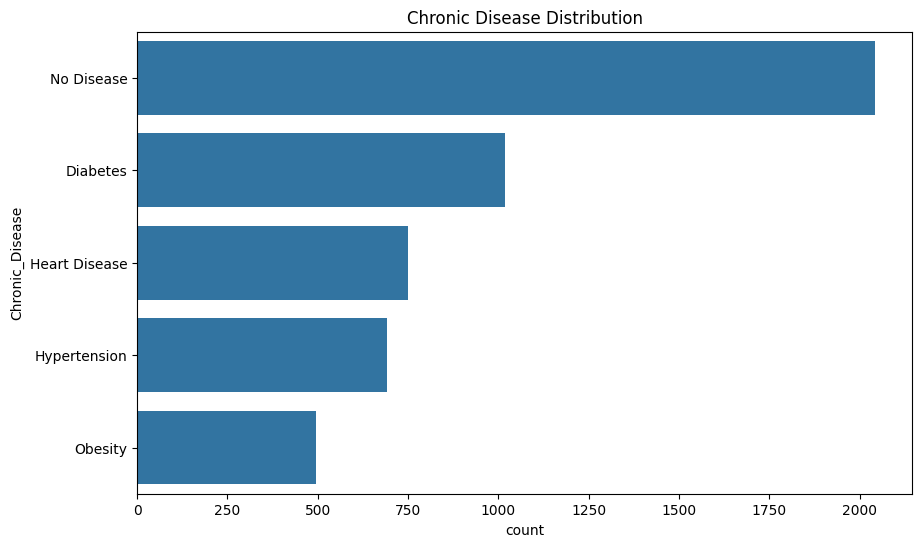

In [21]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    y="Chronic_Disease",
    order=df["Chronic_Disease"].value_counts().index
)

plt.title("Chronic Disease Distribution")

plt.savefig("../reports/figures/disease_distribution.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

Observation
No Disease is the most frequent category.
Diabetes is the second most common condition.
Heart Disease and Hypertension occur at moderate frequencies.
Obesity is the least represented disease category.
Interpretation

The dataset reflects a realistic clinical scenario where healthy individuals outnumber patients with chronic diseases.

ML Impact

Disease status is likely to contribute significantly to personalized diet recommendations and should be retained as an important categorical feature.

Meal Plan Distribution

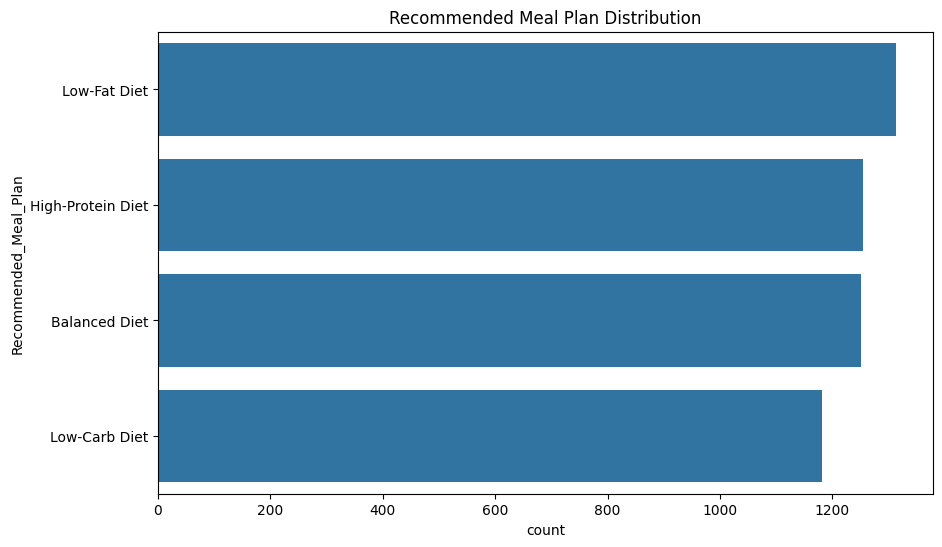

In [22]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    y="Recommended_Meal_Plan",
    order=df["Recommended_Meal_Plan"].value_counts().index
)

plt.title("Recommended Meal Plan Distribution")

plt.savefig("../reports/figures/meal_plan_distribution.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

Observation
The four recommended meal plans are relatively balanced.
Low-Fat Diet appears slightly more frequent.
Low-Carb Diet appears slightly less frequent.
Interpretation

The classification target is well distributed across all meal plan categories.

ML Impact

Excellent news!

No class imbalance techniques (SMOTE, oversampling, etc.) appear necessary.

Correlation Heatmap

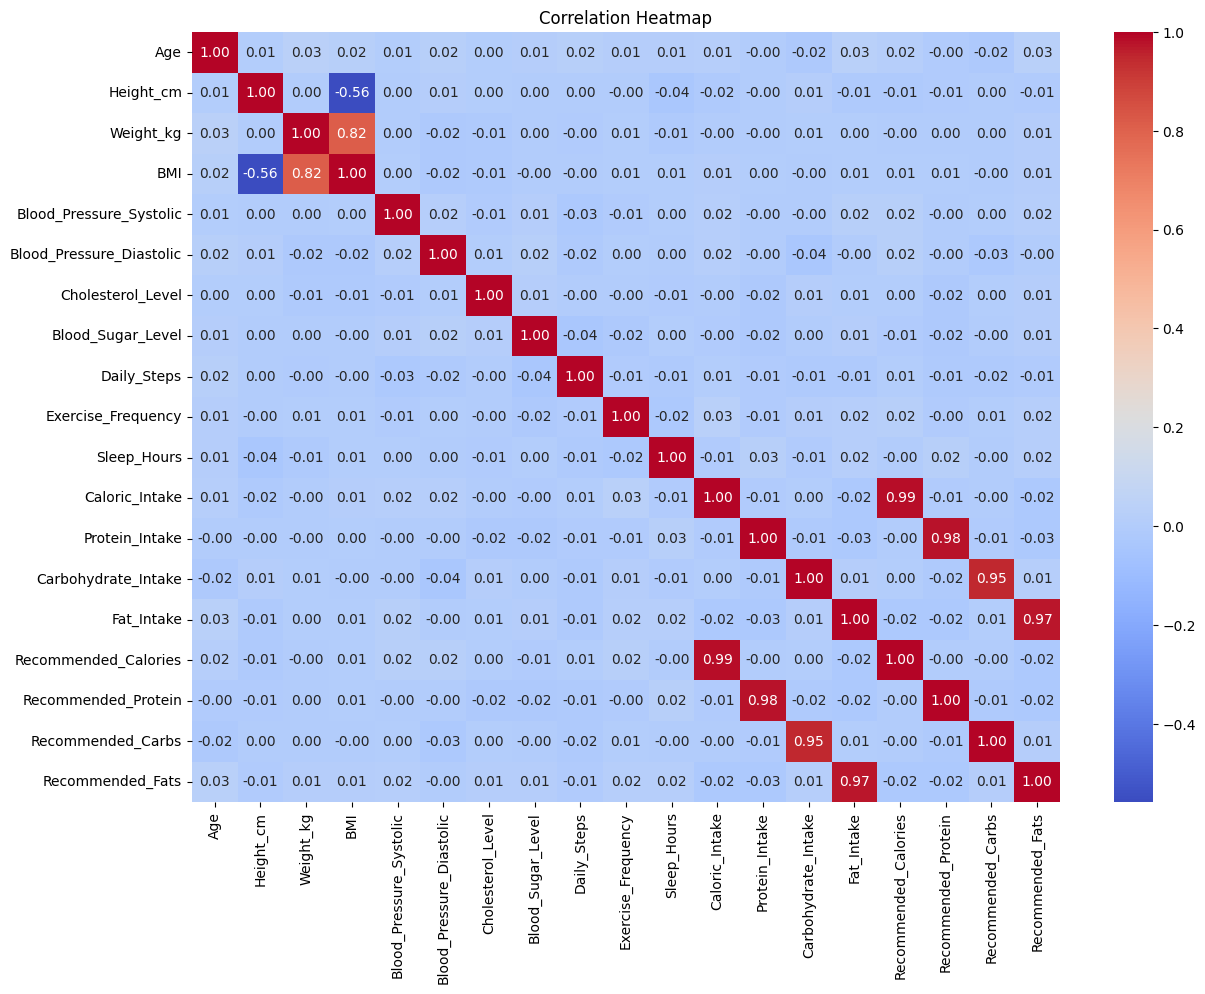

In [23]:
plt.figure(figsize=(14,10))

corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.savefig("../reports/figures/correlation_heatmap.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

Observation
Most clinical variables show very weak correlations with each other.
Weight (0.82) has a strong positive correlation with BMI, which is expected because BMI is calculated using weight and height.
Height (-0.56) has a moderate negative correlation with BMI.
Current nutritional intake features show very strong positive correlations with their corresponding recommendation targets:
Caloric_Intake ↔ Recommended_Calories (0.99)
Protein_Intake ↔ Recommended_Protein (0.98)
Carbohydrate_Intake ↔ Recommended_Carbs (0.95)
Fat_Intake ↔ Recommended_Fats (0.97)
Interpretation

The strong relationships between current nutritional intake and recommended nutritional values indicate that the recommendation system is largely influenced by a patient's existing dietary intake.

Apart from BMI-related variables, most medical and lifestyle features are only weakly correlated with one another. This suggests that each feature contributes unique information rather than duplicating another feature.

Machine Learning Impact
✅ Very Good News

There is very little multicollinearity among most predictor variables.

This means:

Tree-based models such as Random Forest, XGBoost, and Gradient Boosting should perform well.
Most features can be retained because they provide independent information.

BMI vs Recommended Calories

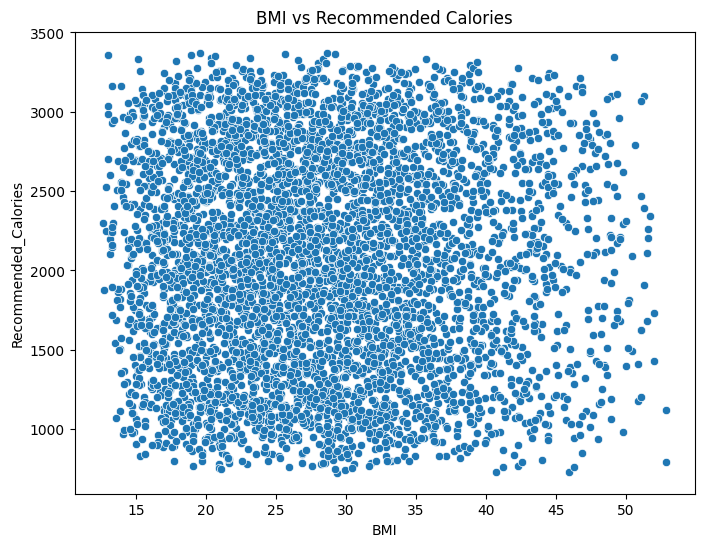

In [24]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="BMI",
    y="Recommended_Calories"
)

plt.title("BMI vs Recommended Calories")

plt.savefig("../reports/figures/bmi_vs_calories.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

Observation

The scatter plot does not show a strong linear relationship between BMI and Recommended Calories.
Points are widely dispersed.

Interpretation

Recommended calorie intake is influenced by multiple variables, not BMI alone.

ML Impact

This confirms our decision to use multiple features rather than relying on BMI only.

This is actually a positive finding—it justifies using machine learning.

Blood Sugar vs Disease

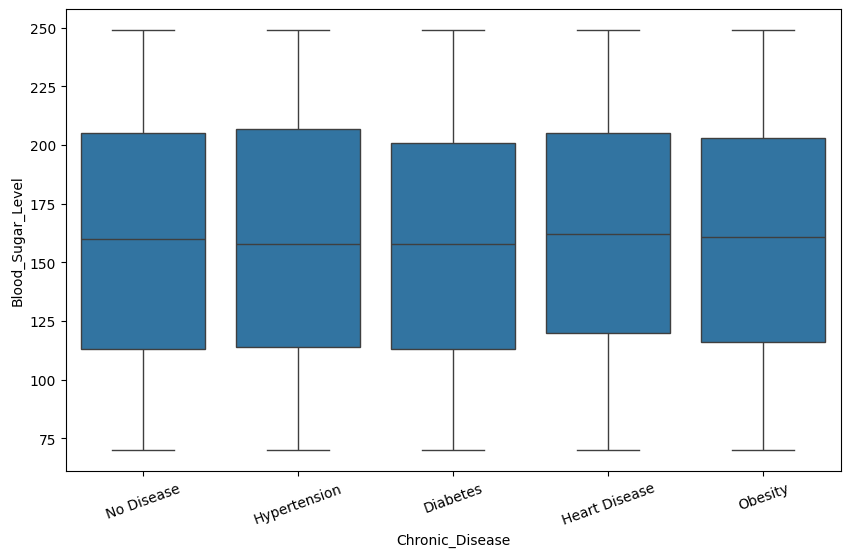

In [25]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x="Chronic_Disease",
    y="Blood_Sugar_Level"
)

plt.xticks(rotation=20)

plt.savefig("../reports/figures/blood_sugar_vs_disease.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

Observation

Blood sugar values overlap considerably across disease categories.
Median blood sugar levels are broadly similar, although variability exists.

Interpretation

Blood sugar alone does not clearly distinguish disease groups.
Disease prediction depends on a combination of clinical factors.

ML Impact

Blood sugar remains useful but should be combined with BMI, blood pressure, cholesterol, lifestyle, and other features.

Calories Distribution

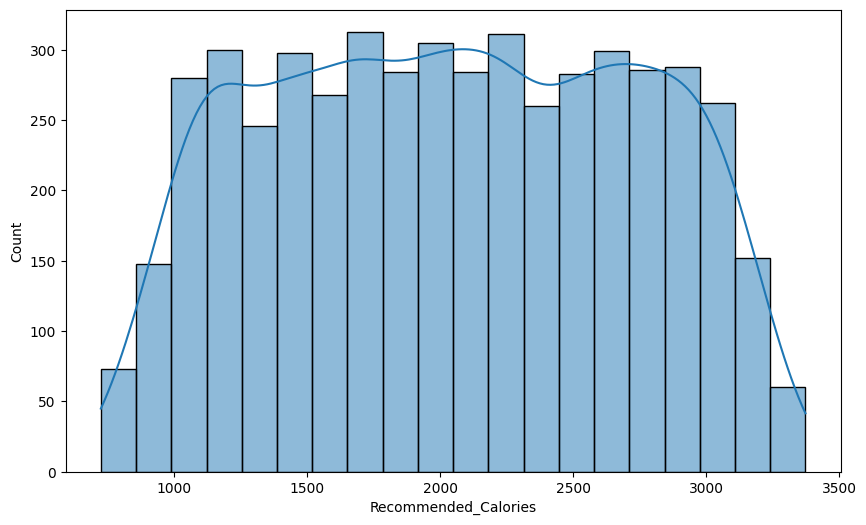

In [26]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["Recommended_Calories"],
    kde=True
)

plt.savefig("../reports/figures/recommended_calories_distribution.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

Observation
Recommended calorie values are distributed across a broad range.
The distribution is reasonably smooth without extreme spikes.
Most recommendations fall between approximately 1200 and 3000 kcal.
Interpretation

The regression target contains sufficient variability for the model to learn meaningful calorie predictions.

ML Impact

Regression models are expected to perform well due to the continuous and well-distributed target variable.

Outlier Detection

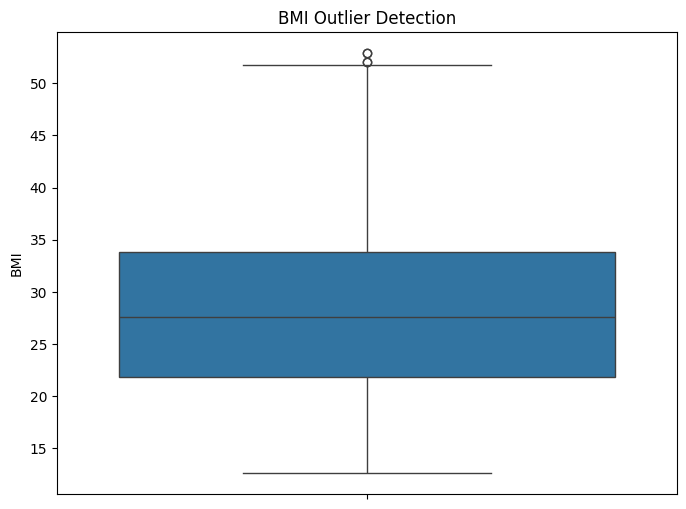

In [27]:
plt.figure(figsize=(8,6))

sns.boxplot(
    y=df["BMI"]
)

plt.title("BMI Outlier Detection")

plt.savefig("../reports/figures/bmi_outliers.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

Observation
Very few observations lie beyond the upper whisker.
No extreme abnormal values are present.
Interpretation

These observations likely represent genuinely obese patients rather than data entry errors.

ML Impact
Keep the outliers.
Tree-based models (Random Forest, XGBoost) handle them well.

In [29]:
summary = """
# Exploratory Data Analysis Summary

Dataset analysed successfully.

Key observations:

- Patient demographics explored.
- BMI distribution analysed.
- Disease distribution visualized.
- Meal plan distribution explored.
- Correlation heatmap generated.
- BMI shows relationship with recommended calories.
- Dataset is suitable for machine learning.
"""

with open("../reports/insights/eda_summary.md","w") as f:
    f.write(summary)

print("EDA Summary Saved Successfully")

EDA Summary Saved Successfully


# EDA Conclusion

The exploratory analysis indicates that the dataset is well-structured and suitable for machine learning.

## Key Findings

- The dataset contains a balanced distribution of patient ages and genders.
- BMI values follow a realistic distribution with only a few valid high-BMI observations.
- Chronic disease categories reflect realistic healthcare scenarios, with healthy individuals forming the largest group.
- Blood sugar levels alone are insufficient to distinguish disease categories, highlighting the importance of using multiple health-related features.
- Recommended meal plans are well balanced across all classes, making the dataset appropriate for classification tasks.
- Recommended calorie values exhibit a broad and continuous distribution, making them suitable for regression modeling.
- No severe data quality issues or unrealistic values were identified during exploratory analysis.

Overall, the dataset demonstrates good diversity and quality, making it appropriate for developing a hybrid Machine Learning and Expert System for personalized diet recommendation.